# 04 Integration time, frames and saturation

The calculator treats an observation as `n_reads = ceil(total_time / frame_time)` detector frames. The frame time therefore sets the read-noise contribution and is bounded above by saturation. This notebook shows both effects and how to check them.

> Requirements: an editable install (`pip install -e .`), as in notebook 01.

In [1]:
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
from esc_etc import Simulation, use_lazuli_style
use_lazuli_style()

sim = Simulation.from_default(hoststarmag=-0.353, planetdeltamag=20,
                              contrast=1e-8, ppgain=10, separation=0.4)

## 1. Frame time and read noise

Shorter frames mean more reads and more read noise, which matters most early in the integration before the speckle floor takes over. A single 600 s frame is allowed here because the saturation time is about 35,000 s (section 3); for a brighter host that will not be true. `plot_snr_vs_time` accepts `ax=` and `label=`, so several calls can share one axis.

SNR in 600 s with 10 s frames : 8.126
SNR in 600 s with one frame   : 9.164


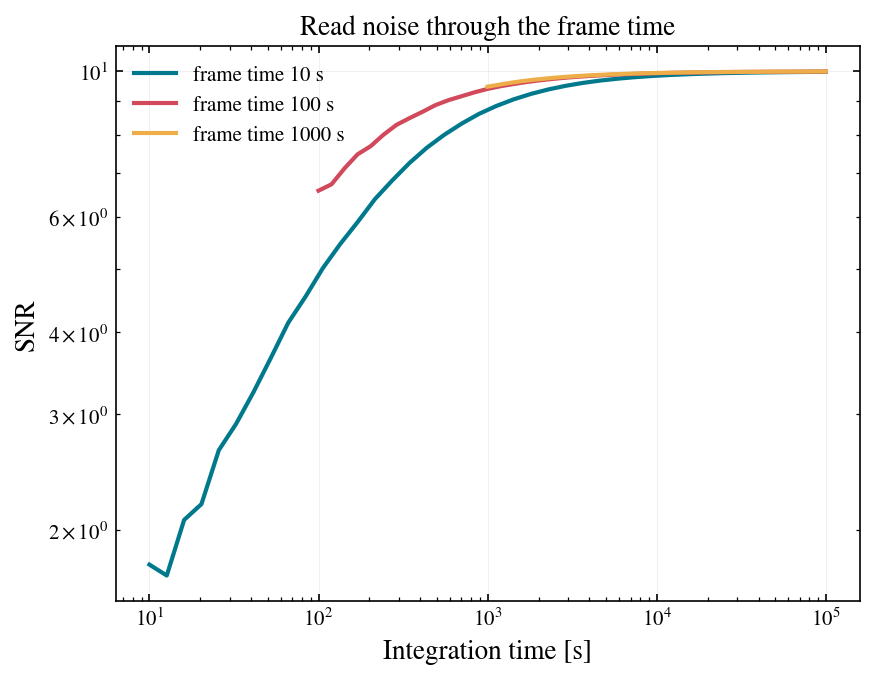

In [2]:
fig, ax = plt.subplots()
for ft in [10, 100, 1000]:
    sim.plot_snr_vs_time(frame_time=ft * u.s, ax=ax, label=f'frame time {ft} s')
ax.set_title('Read noise through the frame time');

t_short = sim.get_snr(600, 10)['snr']
t_long = sim.get_snr(600, 600)['snr']
print('SNR in 600 s with 10 s frames :', round(t_short, 3))
print('SNR in 600 s with one frame   :', round(t_long, 3))
assert t_short < t_long

## 2. Inverting for integration time

`get_int_time_for_snr` returns both the exact (`int_time_continuous`) and the frame-rounded (`int_time`) solution. It returns NaN when the target is above the plateau, which is the calculator telling you that no amount of time will get there.

In [3]:
snr_1h = sim.get_snr(3600, 100)['snr']
back = sim.get_int_time_for_snr(snr_1h, frame_time=100)
print('round trip   :', back['int_time'][0])
assert abs(back['int_time'][0].value - 3600) < 1

unreachable = sim.get_int_time_for_snr(20, frame_time=100)
print('time to SNR 20 with a plateau at 10:', unreachable['int_time_continuous'][0])
assert np.isnan(unreachable['int_time_continuous'][0].value)

round trip   : 3600.0 s
time to SNR 20 with a plateau at 10: nan s


## 3. Saturation

`saturation_time` is the frame time at which the brightest pixel in the planet's photometric aperture reaches `headroom x well_depth`. It counts the planet, the speckles at the dark-hole contrast, the backgrounds and dark current. It does not model the stellar core behind the mask or the bright ring near the inner working angle, so for a bright host the true detector-safe frame time can be much shorter than this number. `is_saturated` compares a frame time against it, and `get_snr` warns when a frame would saturate.

In [4]:
import warnings

t_sat = sim.saturation_time()
print('saturation time        :', t_sat)
print('is_saturated(100 s)    :', bool(sim.is_saturated(100)))
print('is_saturated(2 x t_sat):', bool(sim.is_saturated(2 * t_sat)))

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    sim.get_snr(total_time=4 * t_sat, frame_time=2 * t_sat)
print('warning from get_snr   :', str(caught[0].message)[:60], '...')
assert caught

saturation time        : 47910.5453005843 s


is_saturated(100 s)    : False
is_saturated(2 x t_sat): True


warning from get_snr   : frame_time 95821.0906011686 s exceeds saturation_time 4.79e+ ...


That is the whole calculator. The user guide in the documentation has the equations behind each term, and `esc_etc.plotting` has the raw-array form of every plot used here.